In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive (10).zip to archive (10).zip


In [4]:
import os
import zipfile
import glob
import pandas as pd

# Find the uploaded ZIP file
zip_files = [f for f in uploaded if f.endswith(".zip")]

if not zip_files:
    print("No ZIP file found. Upload the downloaded dataset ZIP.")
else:
    with zipfile.ZipFile(zip_files[0], "r") as z:
        z.extractall("/content/parking_data")

    csv_files = glob.glob(
        "/content/parking_data/**/*.csv",
        recursive=True
    )

    print("CSV files found:", len(csv_files))

    for file in csv_files:
        print("\nFile:", os.path.basename(file))

        df = pd.read_csv(file)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))

CSV files found: 1

File: IIoT_Smart_Parking_Management.csv
Shape: (1000, 28)
Columns: ['Timestamp', 'Parking_Spot_ID', 'Sensor_Reading_Proximity', 'Sensor_Reading_Pressure', 'Vehicle_Type_Weight', 'Vehicle_Type_Height', 'User_Type', 'Weather_Temperature', 'Weather_Precipitation', 'Nearby_Traffic_Level', 'Entry_Time', 'Exit_Time', 'Electric_Vehicle', 'Reserved_Status', 'Occupancy_Rate', 'Payment_Amount', 'Parking_Lot_Section', 'Payment_Status', 'Occupancy_Status', 'Vehicle_Type', 'Parking_Violation', 'Sensor_Reading_Ultrasonic', 'Parking_Duration', 'Environmental_Noise_Level', 'Dynamic_Pricing_Factor', 'Spot_Size', 'Proximity_To_Exit', 'User_Parking_History']


,Timestamp,Parking_Spot_ID,Sensor_Reading_Proximity,Sensor_Reading_Pressure,Vehicle_Type_Weight,Vehicle_Type_Height,User_Type,Weather_Temperature,Weather_Precipitation,Nearby_Traffic_Level,...,Occupancy_Status,Vehicle_Type,Parking_Violation,Sensor_Reading_Ultrasonic,Parking_Duration,Environmental_Noise_Level,Dynamic_Pricing_Factor,Spot_Size,Proximity_To_Exit,User_Parking_History
0,2021-01-01 00:00:00.000000000,20,1.023651,1.541461,1831.770127,4.392528,Visitor,18.092553,1,Low,...,Occupied,Car,0,102.951052,4,55.620740,0.8,Standard,6.610474,6.660310
1,2021-01-02 06:39:16.756756756,49,3.903349,1.621719,1330.815754,4.595638,Registered,13.397533,0,Low,...,Occupied,Car,0,87.559131,3,56.682386,1.2,Compact,8.678719,6.766187
2,2021-01-03 13:18:33.513513513,38,10.315709,6.292374,1255.134827,4.313721,Registered,21.687410,0,High,...,Vacant,Car,1,100.061854,5,59.239322,0.8,Standard,13.795262,-0.910052
3,2021-01-04 19:57:50.270270270,31,6.588039,1.659870,1523.442919,3.567329,Visitor,18.683461,0,Medium,...,Vacant,Motorcycle,1,110.594598,2,44.545155,0.8,Standard,1.678721,10.415888
4,2021-01-06 02:37:07.027027027,8,8.213969,3.278467,1758.490837,5.145836,Visitor,19.214876,0,High,...,Occupied,Car,0,84.786963,2,48.012604,0.8,Standard,20.012252,4.355544


In [5]:
for file in csv_files:
    df = pd.read_csv(file)

    print("\n", "=" * 50)
    print("FILE:", os.path.basename(file))
    print("Rows and columns:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nStatistical summary:")
    display(df.describe(include="all").T)


FILE: IIoT_Smart_Parking_Management.csv
Rows and columns: (1000, 28)

Data types:
Timestamp                     object
Parking_Spot_ID                int64
Sensor_Reading_Proximity     float64
Sensor_Reading_Pressure      float64
Vehicle_Type_Weight          float64
Vehicle_Type_Height          float64
User_Type                     object
Weather_Temperature          float64
Weather_Precipitation          int64
Nearby_Traffic_Level          object
Entry_Time                     int64
Exit_Time                      int64
Electric_Vehicle               int64
Reserved_Status                int64
Occupancy_Rate               float64
Payment_Amount               float64
Parking_Lot_Section           object
Payment_Status                object
Occupancy_Status              object
Vehicle_Type                  object
Parking_Violation              int64
Sensor_Reading_Ultrasonic    float64
Parking_Duration               int64
Environmental_Noise_Level    float64
Dynamic_Pricing_Factor       

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Timestamp,1000,1000,2024-06-30 00:00:00.000000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Parking_Spot_ID,1000.0,NaN,NaN,NaN,25.498,14.878554,1.0,12.75,26.0,38.25,50.0
Sensor_Reading_Proximity,1000.0,NaN,NaN,NaN,5.175569,5.237664,0.016117,1.379257,3.656676,7.145284,37.208615
Sensor_Reading_Pressure,1000.0,NaN,NaN,NaN,4.041883,2.816151,0.051721,1.931423,3.458518,5.376865,27.220465
Vehicle_Type_Weight,1000.0,NaN,NaN,NaN,1486.055775,303.834774,597.710298,1284.738158,1486.16044,1675.79088,2472.927891
Vehicle_Type_Height,1000.0,NaN,NaN,NaN,4.985622,0.983682,1.823296,4.332522,4.991352,5.660101,8.11291
User_Type,1000,3,Registered,732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather_Temperature,1000.0,NaN,NaN,NaN,19.803156,5.200571,3.894918,16.255231,19.709048,23.483265,37.645276
Weather_Precipitation,1000.0,NaN,NaN,NaN,0.095,0.293362,0.0,0.0,0.0,0.0,1.0
Nearby_Traffic_Level,1000,3,Low,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
import pandas as pd
import numpy as np

# Load the actual CSV
df = pd.read_csv(csv_files[0])

# Convert timestamp
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

# Check data quality
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nInvalid timestamp rows:",
      df["Timestamp"].isna().sum())

print("\nDuration = 0:",
      (df["Parking_Duration"] == 0).sum())

print("Negative parking duration:",
      (df["Parking_Duration"] < 0).sum())

print("Negative parking history:",
      (df["User_Parking_History"] < 0).sum())

print("\nOccupancy rate outside [0, 1]:",
      ((df["Occupancy_Rate"] < 0) |
       (df["Occupancy_Rate"] > 1)).sum())

print("\nOccupancy status counts:")
print(df["Occupancy_Status"].value_counts())

print("\nZone-wise records:")
print(df["Parking_Lot_Section"].value_counts())

print("\nTimestamp range:")
print(df["Timestamp"].min(), "to", df["Timestamp"].max())

print("\nDuration by occupancy status:")
display(df.groupby("Occupancy_Status")["Parking_Duration"].describe())

Dataset shape: (1000, 28)
Missing values: 0
Duplicate rows: 0

Invalid timestamp rows: 0

Duration = 0: 53
Negative parking duration: 0
Negative parking history: 5

Occupancy rate outside [0, 1]: 0

Occupancy status counts:
Occupancy_Status
Occupied    550
Vacant      450
Name: count, dtype: int64

Zone-wise records:
Parking_Lot_Section
Zone A    382
Zone B    307
Zone C    197
Zone D    114
Name: count, dtype: int64

Timestamp range:
2021-01-01 00:00:00 to 2024-06-30 00:00:00

Duration by occupancy status:


,count,mean,std,min,25%,50%,75%,max
Occupancy_Status,,,,,,,,
Occupied,550.0,2.834545,1.607102,0.0,2.0,3.0,4.0,10.0
Vacant,450.0,2.922222,1.652613,0.0,2.0,3.0,4.0,8.0


In [7]:
import pandas as pd
import numpy as np

clean_df = df.copy()

text_cols = clean_df.select_dtypes(
    include="object"
).columns

for col in text_cols:
    clean_df[col] = clean_df[col].str.strip()

clean_df["Zero_Duration_Flag"] = (
    clean_df["Parking_Duration"] == 0
)

clean_df["Negative_History_Flag"] = (
    clean_df["User_Parking_History"] < 0
)

clean_df["Date"] = clean_df["Timestamp"].dt.date
clean_df["Year"] = clean_df["Timestamp"].dt.year
clean_df["Month"] = clean_df["Timestamp"].dt.month
clean_df["Day_Name"] = clean_df["Timestamp"].dt.day_name()

clean_df["Peak_Hour"] = clean_df["Entry_Time"].astype(int)

clean_df["Occupied_Flag"] = (
    clean_df["Occupancy_Status"].str.lower() == "occupied"
).astype(int)

print("Cleaned dataset shape:", clean_df.shape)
print("Zero-duration records flagged:",
      clean_df["Zero_Duration_Flag"].sum())
print("Negative-history records flagged:",
      clean_df["Negative_History_Flag"].sum())

display(clean_df.head())

Cleaned dataset shape: (1000, 36)
Zero-duration records flagged: 53
Negative-history records flagged: 5


,Timestamp,Parking_Spot_ID,Sensor_Reading_Proximity,Sensor_Reading_Pressure,Vehicle_Type_Weight,Vehicle_Type_Height,User_Type,Weather_Temperature,Weather_Precipitation,Nearby_Traffic_Level,...,Proximity_To_Exit,User_Parking_History,Zero_Duration_Flag,Negative_History_Flag,Date,Year,Month,Day_Name,Peak_Hour,Occupied_Flag
0,2021-01-01 00:00:00.000000000,20,1.023651,1.541461,1831.770127,4.392528,Visitor,18.092553,1,Low,...,6.610474,6.660310,False,False,2021-01-01,2021,1,Friday,18,1
1,2021-01-02 06:39:16.756756756,49,3.903349,1.621719,1330.815754,4.595638,Registered,13.397533,0,Low,...,8.678719,6.766187,False,False,2021-01-02,2021,1,Saturday,3,1
2,2021-01-03 13:18:33.513513513,38,10.315709,6.292374,1255.134827,4.313721,Registered,21.687410,0,High,...,13.795262,-0.910052,False,True,2021-01-03,2021,1,Sunday,13,0
3,2021-01-04 19:57:50.270270270,31,6.588039,1.659870,1523.442919,3.567329,Visitor,18.683461,0,Medium,...,1.678721,10.415888,False,False,2021-01-04,2021,1,Monday,15,0
4,2021-01-06 02:37:07.027027027,8,8.213969,3.278467,1758.490837,5.145836,Visitor,19.214876,0,High,...,20.012252,4.355544,False,False,2021-01-06,2021,1,Wednesday,19,1


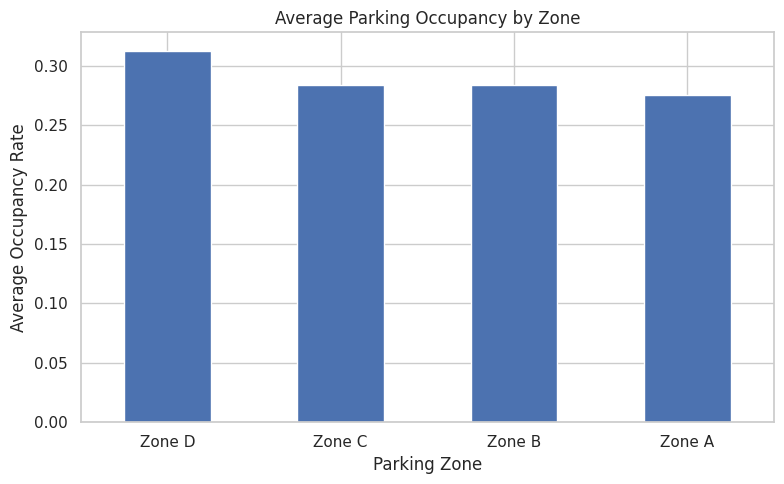

Zone occupancy results:


,Occupancy_Rate
Parking_Lot_Section,
Zone D,0.312476
Zone C,0.283648
Zone B,0.283378
Zone A,0.275270


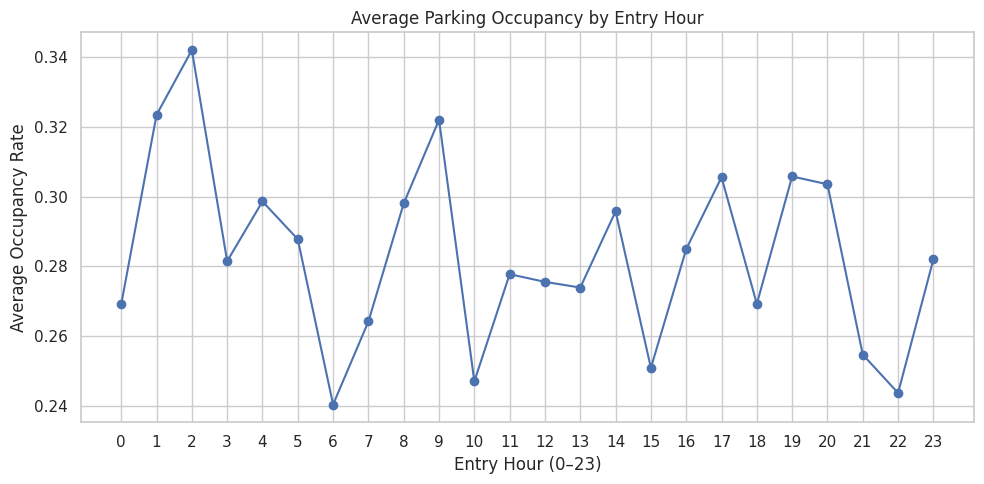

Highest average occupancy hour: 2
Highest hourly average occupancy: 0.342


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Average occupancy rate by zone
zone_occupancy = clean_df.groupby(
    "Parking_Lot_Section"
)["Occupancy_Rate"].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))
zone_occupancy.plot(kind="bar")
plt.title("Average Parking Occupancy by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Average Occupancy Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Zone occupancy results:")
display(zone_occupancy)

# Chart 2: Average occupancy by entry hour
hourly_occupancy = clean_df.groupby(
    "Peak_Hour"
)["Occupancy_Rate"].mean()

plt.figure(figsize=(10, 5))
hourly_occupancy.plot(kind="line", marker="o")
plt.title("Average Parking Occupancy by Entry Hour")
plt.xlabel("Entry Hour (0–23)")
plt.ylabel("Average Occupancy Rate")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

print("Highest average occupancy hour:",
      hourly_occupancy.idxmax())
print("Highest hourly average occupancy:",
      round(hourly_occupancy.max(), 4))

In [9]:
# Weather comparison
weather_summary = clean_df.groupby(
    "Weather_Precipitation"
).agg(
    Records=("Occupancy_Rate", "size"),
    Average_Occupancy=("Occupancy_Rate", "mean"),
    Average_Duration=("Parking_Duration", "mean")
)

print("Weather comparison (0/1 coding):")
display(weather_summary)

# Duration by zone
duration_summary = clean_df.groupby(
    "Parking_Lot_Section"
).agg(
    Sessions=("Parking_Spot_ID", "size"),
    Average_Duration=("Parking_Duration", "mean"),
    Average_Occupancy=("Occupancy_Rate", "mean")
).sort_values("Average_Duration", ascending=False)

print("Duration and occupancy by zone:")
display(duration_summary)

# Occupancy status by zone
status_summary = pd.crosstab(
    clean_df["Parking_Lot_Section"],
    clean_df["Occupancy_Status"],
    normalize="index"
).round(3) * 100

print("Occupancy status percentages by zone:")
display(status_summary)

Weather comparison (0/1 coding):


,Records,Average_Occupancy,Average_Duration
Weather_Precipitation,,,
0,905,0.283382,2.882873
1,95,0.286215,2.789474


Duration and occupancy by zone:


,Sessions,Average_Duration,Average_Occupancy
Parking_Lot_Section,,,
Zone D,114,3.043860,0.312476
Zone C,197,2.898477,0.283648
Zone B,307,2.869707,0.283378
Zone A,382,2.814136,0.275270


Occupancy status percentages by zone:


Occupancy_Status,Occupied,Vacant
Parking_Lot_Section,,
Zone A,57.1,42.9
Zone B,56.7,43.3
Zone C,48.7,51.3
Zone D,54.4,45.6


In [10]:
output_path = "/content/parking_utilization_cleaned.csv"

clean_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /content/parking_utilization_cleaned.csv


In [12]:
from google.colab import files
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
from google.colab import files

uploaded = files.upload()

Saving parking_utilization_cleaned.csv to parking_utilization_cleaned (1).csv


In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv("parking_utilization_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["Occupancy_Status"].value_counts())

Dataset shape: (1000, 36)

Available columns:
['Timestamp', 'Parking_Spot_ID', 'Sensor_Reading_Proximity', 'Sensor_Reading_Pressure', 'Vehicle_Type_Weight', 'Vehicle_Type_Height', 'User_Type', 'Weather_Temperature', 'Weather_Precipitation', 'Nearby_Traffic_Level', 'Entry_Time', 'Exit_Time', 'Electric_Vehicle', 'Reserved_Status', 'Occupancy_Rate', 'Payment_Amount', 'Parking_Lot_Section', 'Payment_Status', 'Occupancy_Status', 'Vehicle_Type', 'Parking_Violation', 'Sensor_Reading_Ultrasonic', 'Parking_Duration', 'Environmental_Noise_Level', 'Dynamic_Pricing_Factor', 'Spot_Size', 'Proximity_To_Exit', 'User_Parking_History', 'Zero_Duration_Flag', 'Negative_History_Flag', 'Date', 'Year', 'Month', 'Day_Name', 'Peak_Hour', 'Occupied_Flag']

Target distribution:
Occupancy_Status
Occupied    550
Vacant      450
Name: count, dtype: int64


Accuracy: 0.4850 (48.50%)
Weighted F1-score: 0.4780

Classification Report:
              precision    recall  f1-score   support

    Occupied       0.53      0.60      0.56       110
      Vacant       0.41      0.34      0.38        90

    accuracy                           0.48       200
   macro avg       0.47      0.47      0.47       200
weighted avg       0.48      0.48      0.48       200


Confusion Matrix:
[[66 44]
 [59 31]]


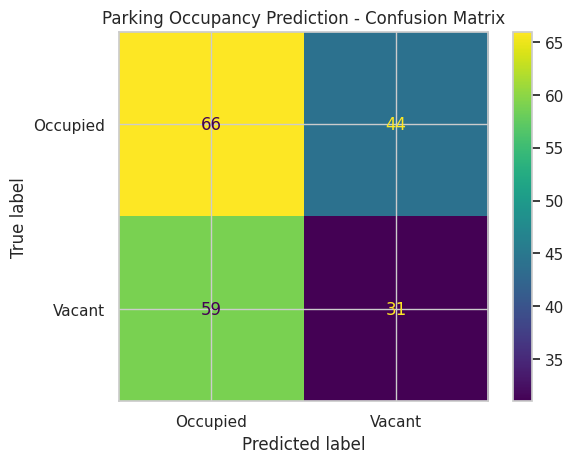

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select useful input features
features = [
    "Entry_Time",
    "Weather_Temperature",
    "Weather_Precipitation",
    "Nearby_Traffic_Level",
    "Vehicle_Type",
    "Parking_Lot_Section",
    "Spot_Size",
    "Reserved_Status",
    "Electric_Vehicle"
]

target = "Occupancy_Status"

# Keep only the required columns
data = df[features + [target]].copy()

# Remove rows without a target label
data = data.dropna(subset=[target])

X = data[features]
y = data[target].astype(str).str.strip()

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in features if col not in numeric_features
]

# Preprocess numerical and categorical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Build the ML pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
accuracy = accuracy_score(y_test, y_pred)
weighted_f1 = f1_score(y_test, y_pred, average="weighted")

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Weighted F1-score: {weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Parking Occupancy Prediction - Confusion Matrix")
plt.show()

In [16]:
# Check target distribution
print("Target distribution:")
print(df["Occupancy_Status"].value_counts(normalize=True).round(3))

# Compare occupancy status with categorical features
for col in [
    "Parking_Lot_Section",
    "Vehicle_Type",
    "Nearby_Traffic_Level",
    "Reserved_Status",
    "Electric_Vehicle"
]:
    print(f"\n--- {col} vs Occupancy_Status ---")
    print(pd.crosstab(
        df[col],
        df["Occupancy_Status"],
        normalize="index"
    ).round(3))

# Compare numerical features by occupancy status
numeric_cols = [
    "Entry_Time",
    "Weather_Temperature",
    "Weather_Precipitation",
    "Occupancy_Rate",
    "Parking_Duration"
]

print("\nNumerical feature averages by occupancy status:")
print(df.groupby("Occupancy_Status")[numeric_cols].mean().round(3))

Target distribution:
Occupancy_Status
Occupied    0.55
Vacant      0.45
Name: proportion, dtype: float64

--- Parking_Lot_Section vs Occupancy_Status ---
Occupancy_Status     Occupied  Vacant
Parking_Lot_Section                  
Zone A                  0.571   0.429
Zone B                  0.567   0.433
Zone C                  0.487   0.513
Zone D                  0.544   0.456

--- Vehicle_Type vs Occupancy_Status ---
Occupancy_Status  Occupied  Vacant
Vehicle_Type                      
Car                  0.560   0.440
Electric Vehicle     0.476   0.524
Motorcycle           0.555   0.445

--- Nearby_Traffic_Level vs Occupancy_Status ---
Occupancy_Status      Occupied  Vacant
Nearby_Traffic_Level                  
High                     0.485   0.515
Low                      0.552   0.448
Medium                   0.568   0.432

--- Reserved_Status vs Occupancy_Status ---
Occupancy_Status  Occupied  Vacant
Reserved_Status                   
0                    0.552   0.448
1     

Feature averages by occupancy status:
                 Sensor_Reading_Proximity                \
                                     mean median    std   
Occupancy_Status                                          
Occupied                            5.352  3.674  5.685   
Vacant                              4.960  3.648  4.630   

                 Sensor_Reading_Pressure                \
                                    mean median    std   
Occupancy_Status                                         
Occupied                           4.075  3.476  2.898   
Vacant                             4.001  3.429  2.716   

                 Sensor_Reading_Ultrasonic                   \
                                      mean   median     std   
Occupancy_Status                                              
Occupied                           101.125  100.257  19.392   
Vacant                              99.636   99.632  21.634   

                 Vehicle_Type_Weight  ... Vehicle_Type_Heig

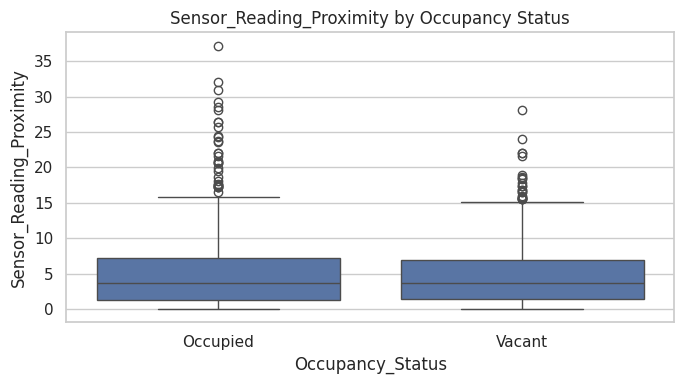

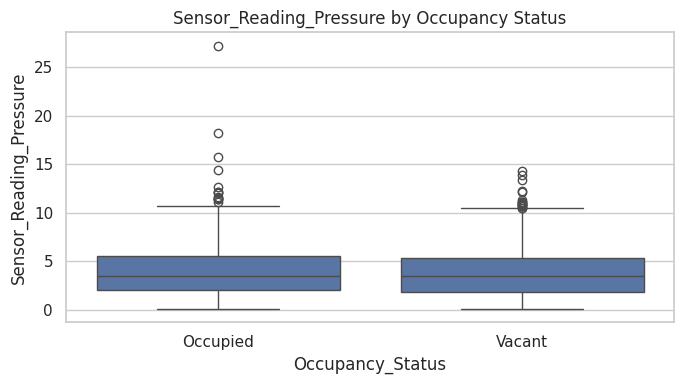

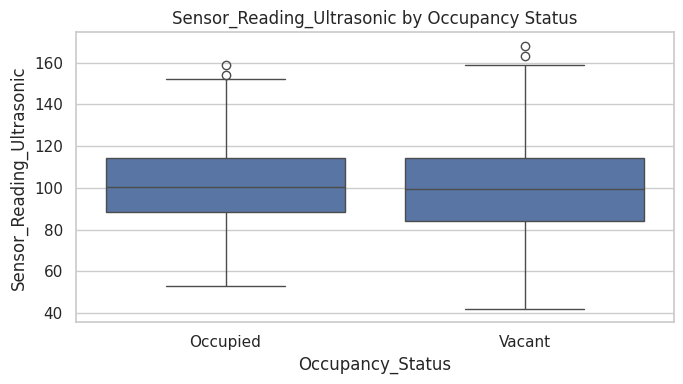

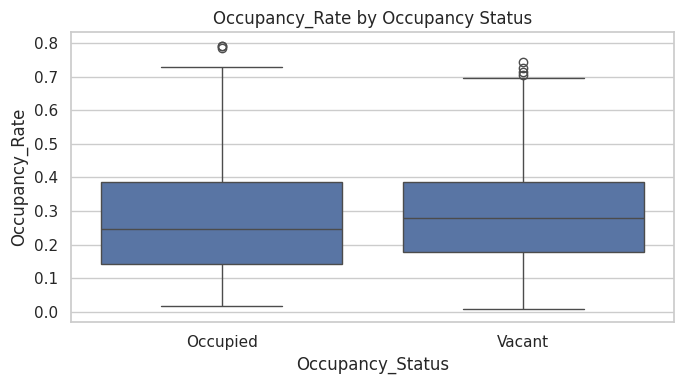

In [17]:
# Investigate sensor and other numerical features
sensor_cols = [
    "Sensor_Reading_Proximity",
    "Sensor_Reading_Pressure",
    "Sensor_Reading_Ultrasonic",
    "Vehicle_Type_Weight",
    "Vehicle_Type_Height",
    "User_Parking_History",
    "Occupancy_Rate",
    "Parking_Duration"
]

print("Feature averages by occupancy status:")
print(
    df.groupby("Occupancy_Status")[sensor_cols]
      .agg(["mean", "median", "std"])
      .round(3)
)

# Visualize how sensor readings vary by status
import matplotlib.pyplot as plt
import seaborn as sns

for col in [
    "Sensor_Reading_Proximity",
    "Sensor_Reading_Pressure",
    "Sensor_Reading_Ultrasonic",
    "Occupancy_Rate"
]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Occupancy_Status", y=col)
    plt.title(f"{col} by Occupancy Status")
    plt.tight_layout()
    plt.show()

In [18]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

# Additional sensor features
features_v2 = [
    "Entry_Time",
    "Weather_Temperature",
    "Weather_Precipitation",
    "Nearby_Traffic_Level",
    "Vehicle_Type",
    "Parking_Lot_Section",
    "Spot_Size",
    "Reserved_Status",
    "Electric_Vehicle",
    "Sensor_Reading_Proximity",
    "Sensor_Reading_Pressure",
    "Sensor_Reading_Ultrasonic",
    "Vehicle_Type_Weight",
    "Vehicle_Type_Height",
    "User_Parking_History"
]

target = "Occupancy_Status"

data_v2 = df[features_v2 + [target]].dropna(subset=[target]).copy()
X_v2 = data_v2[features_v2]
y_v2 = data_v2[target].astype(str).str.strip()

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y_v2,
    test_size=0.20,
    random_state=42,
    stratify=y_v2
)

# Reuse the preprocessing and classifier structure
model_v2 = clone(model)
model_v2.fit(X_train_v2, y_train_v2)

pred_v2 = model_v2.predict(X_test_v2)

acc_v2 = accuracy_score(y_test_v2, pred_v2)
f1_v2 = f1_score(y_test_v2, pred_v2, average="weighted")

print("MODEL COMPARISON")
print("-" * 35)
print(f"Original model accuracy: {accuracy:.3f}")
print(f"Original weighted F1:     {weighted_f1:.3f}")
print()
print(f"Expanded model accuracy:  {acc_v2:.3f}")
print(f"Expanded weighted F1:     {f1_v2:.3f}")

MODEL COMPARISON
-----------------------------------
Original model accuracy: 0.485
Original weighted F1:     0.478

Expanded model accuracy:  0.485
Expanded weighted F1:     0.478


Top 15 feature importances:
                                 Feature  Importance
            numeric__Weather_Temperature    0.365178
                     numeric__Entry_Time    0.268121
               numeric__Electric_Vehicle    0.037683
                numeric__Reserved_Status    0.034119
 categorical__Parking_Lot_Section_Zone A    0.026727
         categorical__Spot_Size_Standard    0.025158
          numeric__Weather_Precipitation    0.025070
 categorical__Parking_Lot_Section_Zone B    0.025028
   categorical__Nearby_Traffic_Level_Low    0.022792
           categorical__Vehicle_Type_Car    0.022518
 categorical__Parking_Lot_Section_Zone C    0.021640
categorical__Nearby_Traffic_Level_Medium    0.021558
          categorical__Spot_Size_Compact    0.020420
 categorical__Parking_Lot_Section_Zone D    0.018514
    categorical__Vehicle_Type_Motorcycle    0.018208


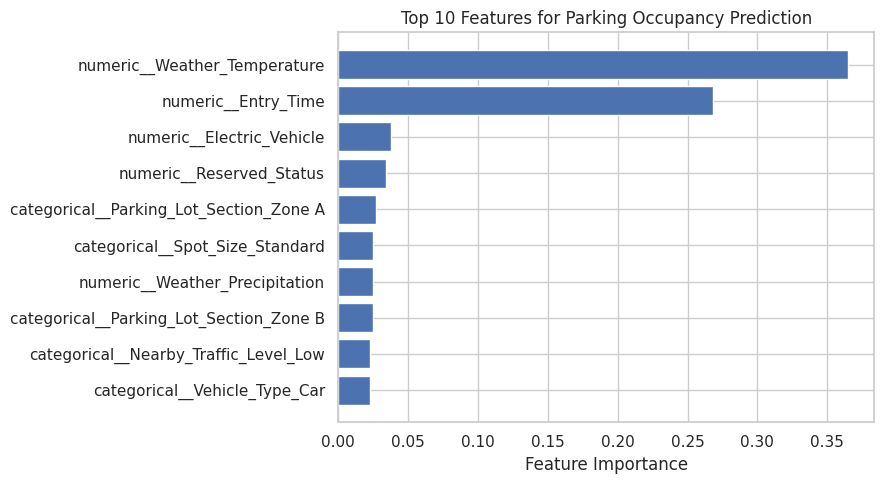

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the encoded feature names and Random Forest
preprocessor = model_v2.named_steps["preprocessor"]
rf = model_v2.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 feature importances:")
print(importance.head(15).to_string(index=False))

# Plot the top 10
top10 = importance.head(10).sort_values("Importance")

plt.figure(figsize=(9, 5))
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features for Parking Occupancy Prediction")
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

    Occupied       0.53      0.60      0.56       110
      Vacant       0.41      0.34      0.38        90

    accuracy                           0.48       200
   macro avg       0.47      0.47      0.47       200
weighted avg       0.48      0.48      0.48       200



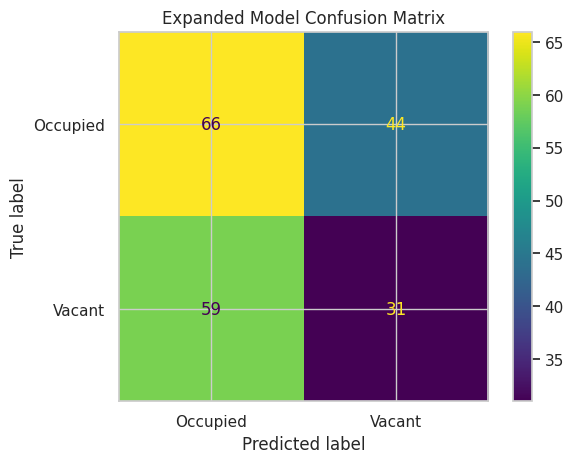

In [20]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(classification_report(
    y_test_v2,
    pred_v2,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_v2,
    pred_v2
)
plt.title("Expanded Model Confusion Matrix")
plt.show()

In [21]:
print("Occupancy rate by status:")
print(
    df.groupby("Occupancy_Status")["Occupancy_Rate"]
      .describe()
      .round(3)
)

print("\nCorrelation between numerical features:")
print(
    df[[
        "Occupancy_Rate",
        "Entry_Time",
        "Weather_Temperature",
        "Sensor_Reading_Proximity",
        "Sensor_Reading_Pressure",
        "Sensor_Reading_Ultrasonic"
    ]].corr().round(2)
)

Occupancy rate by status:
                  count   mean    std    min    25%    50%    75%    max
Occupancy_Status                                                        
Occupied          550.0  0.274  0.162  0.018  0.142  0.247  0.386  0.793
Vacant            450.0  0.295  0.159  0.008  0.179  0.278  0.387  0.743

Correlation between numerical features:
                           Occupancy_Rate  Entry_Time  Weather_Temperature  \
Occupancy_Rate                       1.00       -0.04                -0.02   
Entry_Time                          -0.04        1.00                -0.02   
Weather_Temperature                 -0.02       -0.02                 1.00   
Sensor_Reading_Proximity            -0.03       -0.02                 0.00   
Sensor_Reading_Pressure             -0.03        0.03                 0.01   
Sensor_Reading_Ultrasonic            0.01        0.00                 0.02   

                           Sensor_Reading_Proximity  Sensor_Reading_Pressure  \
Occupancy_Rate

In [22]:
results = X_test_v2.copy()
results["Actual_Status"] = y_test_v2.values
results["Predicted_Status"] = pred_v2

results.to_csv("parking_ml_predictions.csv", index=False)

from google.colab import files
files.download("parking_ml_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

report = f"""
PARKING UTILIZATION INSIGHT
MACHINE LEARNING EVALUATION REPORT

Algorithm: Random Forest Classifier
Dataset records: {len(df)}
Test records: {len(y_test_v2)}

Original model accuracy: {accuracy:.2%}
Original weighted F1-score: {weighted_f1:.3f}

Expanded model accuracy: {acc_v2:.2%}
Expanded weighted F1-score: {f1_v2:.3f}

Classification Report:
{classification_report(y_test_v2, pred_v2, zero_division=0)}

Conclusion:
The expanded model achieved the same performance as the original
model on the same test split. Additional sensor features did not
improve predictive performance. The dataset's features and target
relationship require further investigation before this model can
be recommended for real-world parking predictions.
"""

print(report)

with open("parking_ml_evaluation_report.txt", "w") as f:
    f.write(report)

from google.colab import files
files.download("parking_ml_evaluation_report.txt")


PARKING UTILIZATION INSIGHT
MACHINE LEARNING EVALUATION REPORT

Algorithm: Random Forest Classifier
Dataset records: 1000
Test records: 200

Original model accuracy: 48.50%
Original weighted F1-score: 0.478

Expanded model accuracy: 48.50%
Expanded weighted F1-score: 0.478

Classification Report:
              precision    recall  f1-score   support

    Occupied       0.53      0.60      0.56       110
      Vacant       0.41      0.34      0.38        90

    accuracy                           0.48       200
   macro avg       0.47      0.47      0.47       200
weighted avg       0.48      0.48      0.48       200


Conclusion:
The expanded model achieved the same performance as the original
model on the same test split. Additional sensor features did not
improve predictive performance. The dataset's features and target
relationship require further investigation before this model can
be recommended for real-world parking predictions.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>